# K-nearest neighbors for loan default

Train and compare KNN classifiers on the shared training and test partitions from [03_feature_engineering.ipynb](03_feature_engineering.ipynb). The pipeline standardizes numeric predictors before distance calculations. Hyperparameters and the decision threshold are selected using stratified cross-validation on the training partition only; the held-out test partition is reserved for final evaluation.

The reported metric columns match [04b_model_logistic_regression.ipynb](04b_model_logistic_regression.ipynb) and [04c_model_xgboost.ipynb](04c_model_xgboost.ipynb), so results can be compared or stacked in notebook 05.


## 1. Load the shared training and test data


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, auc, brier_score_loss, confusion_matrix, f1_score,
    log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier


In [4]:
ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data' / 'financial_loan_dataset_v2.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the project folder or its notebooks directory.')
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
TARGET = 'loan_default'
SEED = 42

split_paths = [DATA_DIR / filename for filename in ('train.csv', 'test.csv')]
if not all(path.is_file() for path in split_paths):
    raise FileNotFoundError('Run 03_feature_engineering.ipynb to generate train.csv and test.csv.')

train_df, test_df = (pd.read_csv(path) for path in split_paths)
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f'Train: {len(y_train):,} rows | Test: {len(y_test):,} rows')
print(f'Default rate: train {y_train.mean():.1%} | test {y_test.mean():.1%}')


Train: 960 rows | Test: 240 rows
Default rate: train 20.6% | test 20.8%


## 2. Define numeric feature sets

Use the same numeric tabular predictors as the XGBoost comparison, together with the two non-thinking Qwen3.5 numeric scores. `customer_id`, `customer_remark`, the target, and descriptive text labels are excluded from the predictor matrix. The tabular-only experiment removes the two Qwen scores to show their incremental contribution.

Although `credit_score_tier` is a categorical concept, the shared feature table stores it as an ordinal numeric tier (1–4); KNN therefore treats it as a scaled numeric feature. Employment indicators are already one-hot encoded.


In [5]:
qwen_cols = ['slm_sentiment_score', 'slm_strain_score']
tabular_cols = [
    'age', 'annual_income', 'credit_score', 'credit_score_tier', 'loan_amount',
    'debt_to_income_ratio', 'late_payments_12m', 'account_tenure_months',
    'loan_to_income_ratio', 'total_burden_ratio', 'residual_monthly_income',
    'late_payment_intensity', 'credit_utilization_stress', 'risk_adjusted_leverage',
    'employment_stability_score',
]
knn_cols = tabular_cols + qwen_cols

missing = sorted(set(knn_cols + [TARGET]) - set(train_df.columns))
if missing:
    raise KeyError(f'Missing expected training columns: {missing}')
if train_df[knn_cols].isna().any().any() or test_df[knn_cols].isna().any().any():
    raise ValueError('KNN predictors contain missing values; add imputation inside the pipeline before fitting.')
print(f'{len(tabular_cols)} tabular predictors + {len(qwen_cols)} Qwen scores')


15 tabular predictors + 2 Qwen scores


## 3. Tune KNN with training-only cross-validation

KNN classifies a borrower from nearby training examples. Standardization is fitted inside each cross-validation fold because distance calculations are sensitive to feature scale. Grid search selects the number of neighbours, distance weighting, and Minkowski distance (`p=1` Manhattan or `p=2` Euclidean) by mean ROC AUC across five stratified folds.

After selecting the hyperparameters, out-of-fold training probabilities are used to choose a threshold that maximizes macro F1. The test data is not used for either choice.


In [6]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_jobs=1),
)
param_grid = {
    'kneighborsclassifier__n_neighbors': [5, 11, 21, 31],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__p': [1, 2],
}
search = GridSearchCV(
    knn_pipeline,
    param_grid,
    scoring='roc_auc',
    cv=folds,
    n_jobs=-1,
    refit=True,
)
search.fit(train_df[knn_cols], y_train)
best_params = search.best_params_
print('Best parameters:', best_params)
print(f'Cross-validated ROC AUC: {search.best_score_:.4f}')


Best parameters: {'kneighborsclassifier__n_neighbors': 21, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'distance'}
Cross-validated ROC AUC: 0.8154


In [7]:
oof_probabilities = cross_val_predict(
    search.best_estimator_, train_df[knn_cols], y_train,
    cv=folds, method='predict_proba', n_jobs=-1,
)[:, 1]
thresholds = np.arange(5, 96) / 100
oof_macro_f1 = [
    f1_score(y_train, oof_probabilities >= threshold, average='macro')
    for threshold in thresholds
]
tuned_threshold = thresholds[int(np.argmax(oof_macro_f1))]
print(f'Training-selected threshold: {tuned_threshold:.2f}')
print(f'Out-of-fold macro F1: {max(oof_macro_f1):.4f}')


Training-selected threshold: 0.31
Out-of-fold macro F1: 0.7046


## 4. Evaluate on the held-out test set

Compare default KNN, the tuned tabular-only model, and the tuned model with Qwen scores, all at threshold 0.50. A final row applies the threshold selected from out-of-fold training predictions. Threshold-dependent metrics use class predictions; probability metrics use the predicted default probabilities.


In [8]:
def evaluate_predictions(name, y_true, probabilities, threshold=0.50):
    predicted = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted),
        'Specificity': tn / (tn + fp),
        'F1_Score': f1_score(y_true, predicted),
        'Macro_F1': f1_score(y_true, predicted, average='macro'),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'PR_AUC': auc(recall, precision),
        'Brier_Score': brier_score_loss(y_true, probabilities),
        'Log_Loss': log_loss(y_true, probabilities),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }


def fit_and_predict(features, params):
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=params.get('kneighborsclassifier__n_neighbors', 5),
            weights=params.get('kneighborsclassifier__weights', 'uniform'),
            p=params.get('kneighborsclassifier__p', 2),
            n_jobs=1,
        ),
    )
    model.fit(train_df[features], y_train)
    return model, model.predict_proba(test_df[features])[:, 1]


In [9]:
default_params = {}
_, default_probabilities = fit_and_predict(knn_cols, default_params)
_, tabular_probabilities = fit_and_predict(tabular_cols, best_params)
final_model, final_probabilities = fit_and_predict(knn_cols, best_params)

metrics = pd.DataFrame([
    evaluate_predictions('1. KNN, default parameters + Qwen', y_test, default_probabilities),
    evaluate_predictions('2. KNN tuned, tabular only', y_test, tabular_probabilities),
    evaluate_predictions('3. KNN tuned + Qwen non-thinking', y_test, final_probabilities),
    evaluate_predictions('4. KNN tuned + Qwen non-thinking, tuned threshold',
                         y_test, final_probabilities, tuned_threshold),
])
RESULTS_DIR.mkdir(exist_ok=True)
metrics.to_csv(RESULTS_DIR / 'knn_metrics.csv', index=False)
display(metrics.set_index('Model').round(4))


,Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,Macro_F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,TP,TN,FP,FN
Model,,,,,,,,,,,,,,,
"1. KNN, default parameters + Qwen",0.50,0.8208,0.6296,0.34,0.9474,0.4416,0.6674,0.7582,0.5154,0.1388,1.9284,17,180,10,33
"2. KNN tuned, tabular only",0.50,0.7958,0.5263,0.20,0.9526,0.2899,0.5853,0.7592,0.4429,0.1414,0.7113,10,181,9,40
3. KNN tuned + Qwen non-thinking,0.50,0.8208,0.6842,0.26,0.9684,0.3768,0.6361,0.7696,0.4974,0.1379,0.4325,13,184,6,37
"4. KNN tuned + Qwen non-thinking, tuned threshold",0.31,0.8000,0.5250,0.42,0.9000,0.4667,0.6718,0.7696,0.4974,0.1379,0.4325,21,171,19,29


## 5. Compare ROC curves

ROC curves summarize ranking performance across thresholds. This plot is descriptive: the final reported table and saved CSV remain the primary comparison output.


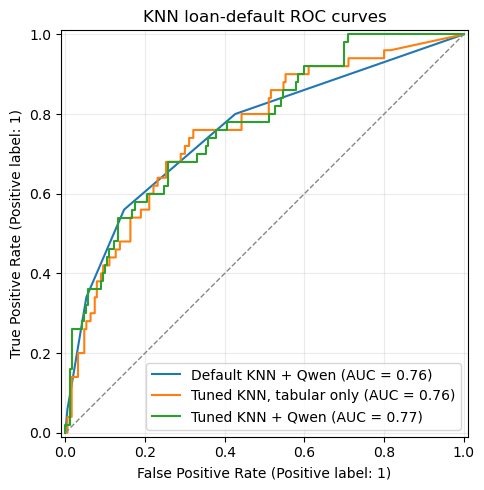

In [10]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, probabilities in [
    ('Default KNN + Qwen', default_probabilities),
    ('Tuned KNN, tabular only', tabular_probabilities),
    ('Tuned KNN + Qwen', final_probabilities),
]:
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='#898781', linewidth=1)
ax.set_title('KNN loan-default ROC curves')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'knn_roc_curve.png', dpi=200)
plt.show()


## 6. Key findings

Use the held-out test metrics above to describe KNN performance against the other models. Compare ROC AUC and PR AUC for ranking, then use recall, precision, F1, and confusion-matrix counts to explain the chosen operating threshold. A tuned threshold trades false positives against missed defaults and should be selected according to the business cost of each error.

The Qwen comparison uses identical tuned hyperparameters and the same test rows for tabular-only and tabular-plus-text-score models. Treat small metric differences cautiously because the test partition is limited in size.
